In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

/kaggle/input/competitions/playground-series-s6e10/sample_submission.csv
/kaggle/input/competitions/playground-series-s6e10/train.csv
/kaggle/input/competitions/playground-series-s6e10/test.csv


In [2]:
df=pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/train.csv')

In [3]:
import seaborn as sns

<Axes: xlabel='satisfaction', ylabel='Age'>

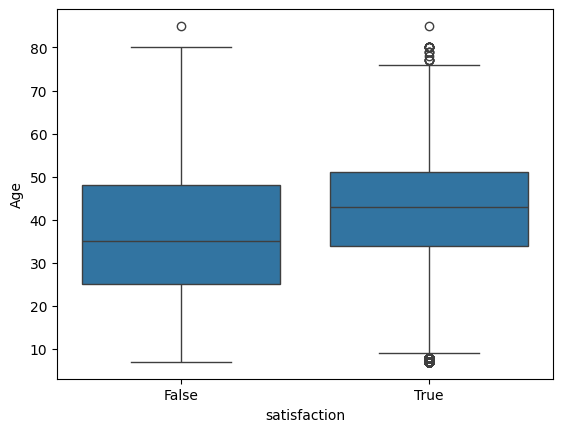

In [4]:
sns.boxplot(df,x='satisfaction',y='Age')

In [5]:
from sklearn.preprocessing import LabelEncoder
le=LabelEncoder()

In [6]:
df['Customer Type'].unique()

array(['Loyal Customer', 'disloyal Customer'], dtype=object)

In [7]:
df['Class'].unique()

array(['Eco', 'Business', 'Eco Plus'], dtype=object)

In [8]:
df['Type of Travel'].unique()

array(['Personal Travel', 'Business travel'], dtype=object)

In [9]:
df['Gender']=le.fit_transform(df['Gender'])
df['Customer Type']=le.fit_transform(df['Customer Type'])
df['Type of Travel']=le.fit_transform(df['Type of Travel'])
df['satisfaction']=le.fit_transform(df['satisfaction'])
df=pd.get_dummies(df,columns=['Class'],drop_first=True)

In [10]:
df.corr(numeric_only=True)

,id,Age,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,Food and drink,Online boarding,Seat comfort,...,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,Gender,Customer Type,Type of Travel,satisfaction,Class_Eco,Class_Eco Plus
id,1.000000,-0.001780,-0.001213,0.000730,-0.001701,-0.000721,-0.000524,-0.000644,0.000996,-0.000571,...,-0.001697,-0.001575,0.001793,0.002248,0.000107,-0.000111,-0.000482,0.000125,-0.000436,0.000755
Age,-0.001780,1.000000,0.190709,0.043137,0.050863,0.043831,0.004095,0.048203,0.287612,0.229095,...,0.069099,0.109591,-0.010311,-0.012882,0.043196,-0.351496,-0.070506,0.202708,-0.196314,-0.022628
Flight Distance,-0.001213,0.190709,1.000000,0.046614,-0.036590,0.087908,0.019533,0.083711,0.310864,0.233666,...,0.104633,0.147663,-0.006978,-0.012248,0.001559,-0.257749,-0.323243,0.370038,-0.505096,-0.113392
Inflight wifi service,0.000730,0.043137,0.046614,1.000000,0.423833,0.771977,0.426632,0.145407,0.488734,0.165905,...,0.057094,0.166201,-0.015971,-0.020250,0.010993,-0.043843,-0.138442,0.291275,-0.095612,0.000609
Departure/Arrival time convenient,-0.001701,0.050863,-0.036590,0.423833,1.000000,0.550840,0.507193,0.006107,0.071405,0.008762,...,0.110153,0.010944,-0.002309,-0.003144,0.020320,-0.247314,0.302899,-0.049185,0.112592,0.019771
Ease of Online booking,-0.000721,0.043831,0.087908,0.771977,0.550840,1.000000,0.580151,0.041581,0.403263,0.066317,...,0.018864,0.047616,-0.005112,-0.006849,0.008004,-0.054772,-0.153903,0.190878,-0.140030,-0.013584
Gate location,-0.000524,0.004095,0.019533,0.426632,0.507193,0.580151,1.000000,0.011033,0.019974,0.017508,...,-0.043934,0.009139,0.003887,0.004771,-0.001534,0.001773,-0.050681,0.022834,-0.020706,-0.000626
Food and drink,-0.000644,0.048203,0.083711,0.145407,0.006107,0.041581,0.011033,1.000000,0.263389,0.656050,...,0.092351,0.678229,-0.013869,-0.020036,-0.001655,-0.074955,-0.080460,0.218058,-0.113682,-0.021750
Online boarding,0.000996,0.287612,0.310864,0.488734,0.071405,0.403263,0.019974,0.263389,1.000000,0.472677,...,0.210361,0.372450,-0.020194,-0.030758,-0.049503,-0.251691,-0.291053,0.559583,-0.405830,-0.071946
Seat comfort,-0.000571,0.229095,0.233666,0.165905,0.008762,0.066317,0.017508,0.656050,0.472677,1.000000,...,0.193581,0.762597,-0.016830,-0.027239,-0.036684,-0.194971,-0.175080,0.401488,-0.292429,-0.064499


<Axes: xlabel='satisfaction', ylabel='Departure Delay in Minutes'>

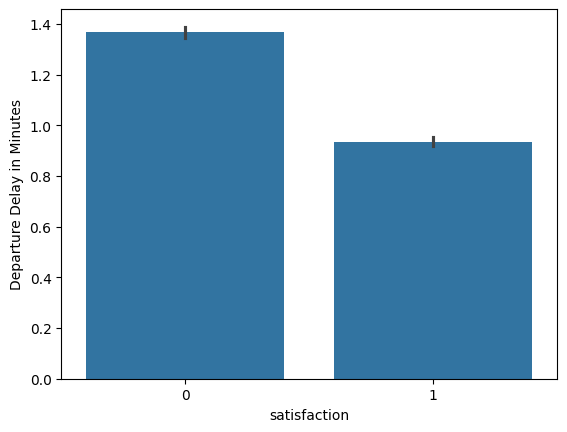

In [11]:
sns.barplot(df,y='Departure Delay in Minutes',x='satisfaction')

In [12]:
df=df.drop(columns=['id','Departure/Arrival time convenient','Arrival Delay in Minutes','Gender'])

In [13]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 699635 entries, 0 to 699634
Data columns (total 20 columns):
 #   Column                      Non-Null Count   Dtype
---  ------                      --------------   -----
 0   Age                         699635 non-null  int64
 1   Flight Distance             699635 non-null  int64
 2   Inflight wifi service       699635 non-null  int64
 3   Ease of Online booking      699635 non-null  int64
 4   Gate location               699635 non-null  int64
 5   Food and drink              699635 non-null  int64
 6   Online boarding             699635 non-null  int64
 7   Seat comfort                699635 non-null  int64
 8   Inflight entertainment      699635 non-null  int64
 9   On-board service            699635 non-null  int64
 10  Leg room service            699635 non-null  int64
 11  Baggage handling            699635 non-null  int64
 12  Checkin service             699635 non-null  int64
 13  Cleanliness                 699635 non-null 

In [14]:
df.isna().sum()

Age                           0
Flight Distance               0
Inflight wifi service         0
Ease of Online booking        0
Gate location                 0
Food and drink                0
Online boarding               0
Seat comfort                  0
Inflight entertainment        0
On-board service              0
Leg room service              0
Baggage handling              0
Checkin service               0
Cleanliness                   0
Departure Delay in Minutes    0
Customer Type                 0
Type of Travel                0
satisfaction                  0
Class_Eco                     0
Class_Eco Plus                0
dtype: int64

In [15]:
ratio = (df['satisfaction'] == 1).sum() / (df['satisfaction'] == 0).sum()
ratio

np.float64(0.797180037811845)

In [16]:
from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import KFold, StratifiedKFold, cross_val_score,cross_val_predict
from sklearn.metrics import confusion_matrix

In [17]:
x=df.drop(columns='satisfaction')
y=df['satisfaction']

In [18]:
fold=StratifiedKFold(n_splits=5,random_state=42,shuffle=True)

In [19]:
model_xgb=XGBClassifier(n_estimators=100,random_state=42,n_jobs=-1)
cv_randomxg=cross_val_score(model_xgb,x,y,cv=fold)

In [20]:
y_pred=cross_val_predict(model_xgb,x,y,cv=fold)

In [21]:
cm=confusion_matrix(y,y_pred)

In [22]:
cm

array([[366641,  22655],
       [ 29709, 280630]])

In [23]:
df=pd.read_csv('/kaggle/input/competitions/playground-series-s6e10/test.csv')

In [24]:
df['Gender']=le.fit_transform(df['Gender'])
df['Customer Type']=le.fit_transform(df['Customer Type'])
df['Type of Travel']=le.fit_transform(df['Type of Travel'])

df=pd.get_dummies(df,columns=['Class'],drop_first=True)

In [25]:
id=df['id']

In [26]:
df=df.drop(columns=['id','Departure/Arrival time convenient','Arrival Delay in Minutes','Gender'])

In [27]:
model_xgb.fit(x,y)



XGBClassifier(base_score=None, booster=None, callbacks=None,
              colsample_bylevel=None, colsample_bynode=None,
              colsample_bytree=None, device=None, early_stopping_rounds=None,
              enable_categorical=True, eval_metric=None, feature_types=None,
              feature_weights=None, gamma=None, grow_policy=None,
              importance_type=None, interaction_constraints=None,
              learning_rate=None, max_bin=None, max_cat_threshold=None,
              max_cat_to_onehot=None, max_delta_step=None, max_depth=None,
              max_leaves=None, min_child_weight=None, missing=nan,
              monotone_constraints=None, multi_strategy=None, n_estimators=100,
              n_jobs=-1, num_parallel_tree=None, ...)

In [28]:
ans=model_xgb.predict_proba(df)[:,1]

In [29]:
out = pd.DataFrame({
    "id":id,
    "satisfaction":ans
})
out.to_csv("submission.csv", index=False)